# Import and Functions

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import sys
import ast
import os
import matplotlib.patheffects as path_effects
sys.path.append('../')
from utils.Evaluation.calculate_metrics import calculate_scores
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as path_effects
sns.set_style(style='whitegrid')  # Better background

In [11]:
def extract_error_types(nested_list):
    return [s.split(':')[0] for sublist in nested_list for s in sublist]

def extract_dfs(df):

    kg_valid_queries_df = df[df['is_KG_Valid_correct']==True].reset_index(drop=True)
    unavailable_output_df = df[df['answer']=="I couldn't find any relevant information in the database"].reset_index(drop=True)
    kg_valid_queries_with_full_schema_df = df[df['is_KG_Valid_correct_with_full_schema']==True].reset_index(drop=True)
    kg_valid_queries_with_filtered_schema_df = df[(df['is_KG_Valid_correct_with_full_schema']==False) & (df['is_KG_Valid_correct']==True)].reset_index(drop=True)

    return kg_valid_queries_df,unavailable_output_df,kg_valid_queries_with_full_schema_df,kg_valid_queries_with_filtered_schema_df

def calculate_LLMetric(df,w1=0.3,w2=0.4,w3=0.1,w4=0.2):
    ''' 
    This function is used to calculate the LLMetric components for a dataframe of the evaluation of LLM
    Input:
        df : A dataframe containing the same columns for each column df (aggregation df)
    '''

    # Calculate percentages for each metric with respect to the total
    df['Pass@1 Rate'] = (df['Pass@1 Output'] / df['Total']) * 100
    df['KG Valid Query Rate'] = (df['KG Valid Query'] / df['Total']) * 100
    df['JaRou Adjustment Factor'] = (df['JaRou(LLMetric)'] / df['KG_Valid_Pass_False_Total']) * 100
    df['Jaccard Adjustment Factor'] = (df['Positive Jaccard Output(LLMetric)'] / df['KG_Valid_Pass_False_Total']) * 100

    df['JaRou Adjustment Factor1'] = (df['JaRou'] / df['Total']) * 100
    df['Jaccard Adjustment Factor1'] = (df['Positive Jaccard Output'] / df['Total']) * 100

    if df['Pass@1 Rate'][0]==df['KG Valid Query Rate'][0]:
        df['LLMetric']=100    

    df['LLMetric'] = w1*df['Pass@1 Rate'] + \
                    w2*df['KG Valid Query Rate'] + \
                    w3*(df['JaRou Adjustment Factor']) + \
                    w4*(df['Jaccard Adjustment Factor'])
    
    df['LLMetric1'] = w1*df['Pass@1 Rate'] + \
                    w2*df['KG Valid Query Rate'] + \
                    w3*(df['JaRou Adjustment Factor1']) + \
                    w4*(df['Jaccard Adjustment Factor1'])
    
    return df

def extract_params(model_name):
    import re
    match = re.search(r'([\d.]+)[bB]', model_name)
    if match:
        return float(match.group(1))
    return 1000  # Default if no match

def calculate_dicts(source_directory,extended=True):
    dict_with_models={}
    for root, dirs, files in os.walk(source_directory):
        for file in files:
            # if file.split('.')[0]!= 'qwen2_5_Coder_32b':
                if file.endswith('.xlsx'):  # Process only .pkl files
                    file_path = os.path.join(root, file)
                    df = pd.read_excel(file_path)
                    print(file_path)
                    if extended:
                        list_columns = ['path','cypher_errors_history', 'cypher_errors']
                        for col in list_columns:
                            df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
                        
                        # Extract error types from cypher_errors_history
                        df['error_codes'] = df['cypher_errors_history'].apply(extract_error_types)
                   
                    # For rows that isKG_Valid_correct is not present, we calculate it
                    if 'is_KG_Valid_correct' not in df.columns:
                        df['is_KG_Valid_correct'] = (
                                                        (df['Schema Valid'] == 1) &
                                                        ((df['Properties Valid'] == 1) | df['Properties Valid'].isna()) &
                                                        (df['Syntax Valid'] == True)
                                                    )
                        df['is_KG_Valid_correct'] = df['is_KG_Valid_correct'].astype(bool)

                    model_name = file.split('.')[0]
                    model_name = model_name.replace('openrouter_', '')
                    model_name = model_name.replace('_local', '')
                    dict_with_models[model_name] = df
    return dict_with_models

# Calculate Melted and Pivot DFs across Models

Define the models mapping and the dataset that we want to evaluate

We end up with two dfs 
 - one melted df
 - one pivoted df

In [12]:
# Combine all metric data into one list
models_mapping = {
    'gpt_4o':'gpt4o', 
    'llama3_2_3b':'Llama-3.2-3B-Instruct',
    'qwen2_5_72b':'Qwen2.5-72B-Instruct',
    'qwen2_5_7b':'Qwen2.5-7B-Instruct',
    'qwen2_5_Coder_32b':'Qwen2.5-Coder-32B-Instruct'
}

dataset = 'SustainDataset'

In [13]:
basic_dfs_dict_full = calculate_dicts("./basic_workflow/Outputs_Evaluation/"+dataset,extended=False)
basic_dfs_dict_filtered = calculate_dicts("./basic_workflow_filtered/Outputs_Evaluation/"+dataset,extended=False)

./basic_workflow/Outputs_Evaluation/SustainDataset/qwen2_5_7b/qwen2_5_7b.xlsx
./basic_workflow/Outputs_Evaluation/SustainDataset/openrouter_qwen2_5_72b/openrouter_qwen2_5_72b.xlsx
./basic_workflow/Outputs_Evaluation/SustainDataset/llama3_2_3b_local/llama3_2_3b_local.xlsx
./basic_workflow/Outputs_Evaluation/SustainDataset/qwen2_5_Coder_32b/qwen2_5_Coder_32b.xlsx
./basic_workflow/Outputs_Evaluation/SustainDataset/gpt_4o/gpt_4o.xlsx
./basic_workflow/Outputs_Evaluation/SustainDataset/gpt_4o/QAChain/gpt_4o.xlsx
./basic_workflow_filtered/Outputs_Evaluation/SustainDataset/qwen2_5_7b/qwen2_5_7b.xlsx
./basic_workflow_filtered/Outputs_Evaluation/SustainDataset/openrouter_qwen2_5_72b/openrouter_qwen2_5_72b.xlsx
./basic_workflow_filtered/Outputs_Evaluation/SustainDataset/llama3_2_3b_local/llama3_2_3b_local.xlsx
./basic_workflow_filtered/Outputs_Evaluation/SustainDataset/qwen2_5_Coder_32b/qwen2_5_Coder_32b.xlsx
./basic_workflow_filtered/Outputs_Evaluation/SustainDataset/gpt_4o/gpt_4o.xlsx


### Calculate Metrics

In [14]:
threshold = 0.8
all_data = []
for phase, model_dict in [('Basic Workflow with Full Schema', basic_dfs_dict_full), ('Basic Workflow with Filtered Schema', basic_dfs_dict_filtered)]:
    for model_name, df in model_dict.items():
        kg_valid_with_pass_false_df = df[(df['is_KG_Valid_correct'] == True) & (df['Pass@1 Output'] ==False)]
        metrics = {
            'KG Valid Query': len(df[df['is_KG_Valid_correct'] == True]),
            'Syntax Valid': len(df[df['Syntax Valid'] == True]),
            'Pass@1 Output': len(df[df['Pass@1 Output'] == True]),
            'Positive Jaccard Output': len(df[df['Jaccard Output'] > 0]),
            'JaRou': len(df[df[['Rouge-L F1-score', 'Jaro Similarity']].mean(axis=1) >= threshold]),
            'Positive Jaccard Output(LLMetric)': len(kg_valid_with_pass_false_df[kg_valid_with_pass_false_df['Jaccard Output'] > 0]),
            'JaRou(LLMetric)': len(kg_valid_with_pass_false_df[kg_valid_with_pass_false_df[['Rouge-L F1-score', 'Jaro Similarity']].mean(axis=1) >= threshold]),
            'Average BLUE score':np.mean(df['BLEU']),
            'Average JaRou Score': df[['Rouge-L F1-score', 'Jaro Similarity']].mean(axis=1).mean(),
            'Average Rouge-L F1-score':np.mean(df["Rouge-L F1-score"]),
            'Average Jaro-Winkler similarity score':np.mean(df["Jaro Similarity"]),
            'Average Jaccard similarity score':np.mean(df["Jaccard Similarity"]),
            'Total':len(df),
            'KG_Valid_Pass_False_Total':len(kg_valid_with_pass_false_df)
        }
        for metric, count in metrics.items():
            all_data.append({
                'Model': models_mapping[model_name],
                'Phase': phase,
                'Metric': metric,
                'Count': count
            })

# Create DataFrame
melted_df = pd.DataFrame(all_data)
melted_df['Params'] = melted_df['Model'].apply(extract_params)
melted_df = melted_df.sort_values(by=['Params'])

df_pivoted = melted_df.pivot(index=['Model', 'Phase','Params'], columns='Metric', values='Count').reset_index()
df_pivoted = df_pivoted.sort_values(by=['Params','Model','Phase'])
df_pivoted = df_pivoted.drop('Params',axis=1)

# two FINAL dfs(one melted one pivoted)
pivot_result = calculate_LLMetric(df_pivoted.copy())
melted_result = pd.melt(pivot_result, id_vars=['Model','Phase'], var_name='Metric', value_name='Count')

### Results for LLMetric

In [17]:
pivot_result[['Model','Phase','LLMetric']]

Metric,Model,Phase,LLMetric
0,Llama-3.2-3B-Instruct,Basic Workflow with Filtered Schema,35.122378
1,Llama-3.2-3B-Instruct,Basic Workflow with Full Schema,33.012821
4,Qwen2.5-7B-Instruct,Basic Workflow with Filtered Schema,23.961538
5,Qwen2.5-7B-Instruct,Basic Workflow with Full Schema,30.064103
6,Qwen2.5-Coder-32B-Instruct,Basic Workflow with Filtered Schema,69.038462
7,Qwen2.5-Coder-32B-Instruct,Basic Workflow with Full Schema,66.089744
2,Qwen2.5-72B-Instruct,Basic Workflow with Filtered Schema,66.538462
3,Qwen2.5-72B-Instruct,Basic Workflow with Full Schema,63.653846
8,gpt4o,Basic Workflow with Filtered Schema,65.192308
9,gpt4o,Basic Workflow with Full Schema,67.910256


In [ ]:
llmetric_df = melted_result[melted_result['Metric'].isin(metrics)].reset_index(drop=True)
result_df = llmetric_df[llmetric_df['Metric']=='LLMetric'] .pivot_table(
    index='Model',
    columns='Phase',
    values='Count'
).reset_index()
result_df['diff'] = result_df['Basic Workflow with Filtered Schema'] - result_df['Basic Workflow with Full Schema']
result_df.loc[:, result_df.columns != 'Model'] = result_df.loc[:, result_df.columns != 'Model'].round(2)
result_df

Phase,Model,Basic Workflow with Filtered Schema,Basic Workflow with Full Schema,diff
0,Llama-3.2-3B-Instruct,35.12,33.01,2.11
1,Qwen2.5-72B-Instruct,66.54,63.65,2.88
2,Qwen2.5-7B-Instruct,23.96,30.06,-6.10
3,Qwen2.5-Coder-32B-Instruct,69.04,66.09,2.95
4,gpt4o,65.19,67.91,-2.72


### Results for Metrics ['Average JaRou Score', 'KG Valid Query','Positive Jaccard Output', 'Pass@1 Output']

In [18]:
pivot_result[['Model','Phase','Average JaRou Score','KG Valid Query', 'Positive Jaccard Output', 'Pass@1 Output']]

Metric,Model,Phase,Average JaRou Score,KG Valid Query,Positive Jaccard Output,Pass@1 Output
0,Llama-3.2-3B-Instruct,Basic Workflow with Filtered Schema,0.732946,20.0,16.0,9.0
1,Llama-3.2-3B-Instruct,Basic Workflow with Full Schema,0.676914,16.0,12.0,7.0
4,Qwen2.5-7B-Instruct,Basic Workflow with Filtered Schema,0.677014,14.0,10.0,9.0
5,Qwen2.5-7B-Instruct,Basic Workflow with Full Schema,0.688517,15.0,12.0,9.0
6,Qwen2.5-Coder-32B-Instruct,Basic Workflow with Filtered Schema,0.842613,42.0,39.0,29.0
7,Qwen2.5-Coder-32B-Instruct,Basic Workflow with Full Schema,0.809338,40.0,37.0,28.0
2,Qwen2.5-72B-Instruct,Basic Workflow with Filtered Schema,0.841446,47.0,38.0,31.0
3,Qwen2.5-72B-Instruct,Basic Workflow with Full Schema,0.836172,42.0,36.0,29.0
8,gpt4o,Basic Workflow with Filtered Schema,0.841996,46.0,37.0,30.0
9,gpt4o,Basic Workflow with Full Schema,0.814799,44.0,41.0,29.0


# Different Plots for all the  Metrics

## Main metrics on the same bar

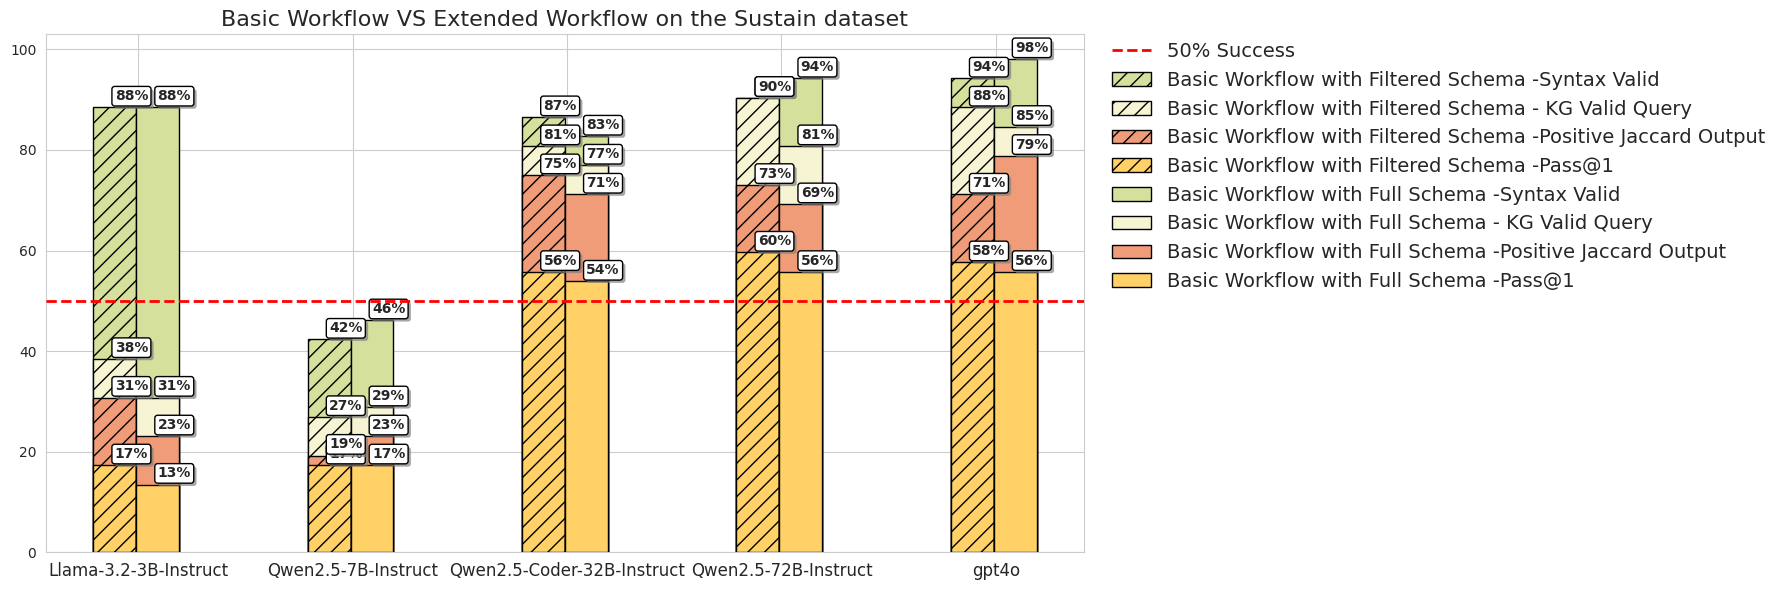

In [19]:
metrics_plot = melted_result[melted_result['Metric'].isin(['KG Valid Query','Syntax Valid','Pass@1 Output','Positive Jaccard Output'])].reset_index(drop=True)
metrics_copy = metrics_plot.copy()

total_df = melted_result[melted_result['Metric']=='Total']

bar_width = 0.2
gap = 0.01  
models = metrics_copy['Model'].unique()
x = list(range(len(models)))
len_df = pivot_result['Total'][0]


offsets = {
    ('KG Valid Query', 'Basic Workflow with Filtered Schema'): -0.5 * bar_width - gap,
    ('KG Valid Query', 'Basic Workflow with Full Schema'): +0.5 * bar_width - gap,
}

fig, ax = plt.subplots(figsize=(18, 6))


# Plot bars and collect bar containers for annotations
kg_valid_bars,syntax_bars,pass_bars,jaccard_bars = [],[],[],[]
for (metric, phase), group_data in metrics_copy[metrics_copy['Metric']=='KG Valid Query'].reset_index(drop=True).groupby(['Metric', 'Phase']):
    xs = [i + offsets[(metric, phase)] for i in x]
    kg_valid_heights,syntax_heights,pass_heights,jaccard_heights = [],[],[],[]
    for model in models:
        metric_phase_df = metrics_copy[(metrics_copy['Model'] == model)& (metrics_copy['Phase'] == phase)]

        kg_valid_heights.append(metric_phase_df[metric_phase_df['Metric']=='KG Valid Query']['Count'].values[0]/len_df*100)  
        syntax_heights.append(metric_phase_df[metric_phase_df['Metric']=='Syntax Valid']['Count'].values[0]/len_df*100)  
        pass_heights.append(metric_phase_df[metric_phase_df['Metric']=='Pass@1 Output']['Count'].values[0]/len_df*100)  
        jaccard_heights.append(metric_phase_df[metric_phase_df['Metric']=='Positive Jaccard Output']['Count'].values[0]/len_df*100)  
    
    if phase == 'Basic Workflow with Full Schema':
        hatch = None
        alpha = 1
    else:
        hatch = '//'
        alpha = None
        
    syntax_bar = ax.bar(xs, syntax_heights, width=bar_width,color='#d4e09b',label=f'{phase} -' + 'Syntax Valid', 
                        edgecolor='black',zorder=3,alpha=alpha,hatch=hatch)
    kg_valid_bar = ax.bar(xs, kg_valid_heights, width=bar_width, label=f'{phase} - {metric}',color='#f6f4d2',
                           edgecolor='black',zorder=3,alpha=alpha,hatch=hatch)
    jaccard_bar = ax.bar(xs, jaccard_heights, width=bar_width, label=f'{phase} -' + 'Positive Jaccard Output',
                  color="#f19c79", edgecolor='black',zorder=3,alpha=alpha,hatch=hatch)
    pass_bar = ax.bar(xs, pass_heights, width=bar_width, label=f'{phase} -' + 'Pass@1',color="#ffd166",
                       edgecolor='black',zorder=3,alpha=alpha,hatch=hatch)
    
    kg_valid_bars.append(kg_valid_bar)
    syntax_bars.append(syntax_bar)
    pass_bars.append(pass_bar)
    jaccard_bars.append(jaccard_bar)

for bar_group_list in [kg_valid_bars,syntax_bars,pass_bars,jaccard_bars]:
    for bar_group in bar_group_list:
        for rect in bar_group:
            height = rect.get_height()
            if height > 0:
                ax.annotate(
                    f'{height:.0f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='left',
                    va='bottom',
                    # rotation=45, 
                    fontsize=10,
                    fontweight='bold' ,
                    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.2',
                              path_effects=[  # <- shadow added to the box
            path_effects.withSimplePatchShadow(offset=(2, -2), shadow_rgbFace='gray', alpha=0.7)
        ]),  # Background color
                )

# Final formatting
ax.set_xticks(x)
ax.set_xticklabels(models,size=12,rotation=0, ha='center')
ax.axhline(y=50, color='red', linewidth=2,linestyle='--', label='50% Success',zorder=3) 
# ax.set_ylabel('Percentage')
ax.set_title('Basic Workflow VS Extended Workflow on the Sustain dataset', fontsize=16)
ax.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.,fontsize=14,framealpha=0)
plt.tight_layout()
plt.show()


## Main metrics side by side and grouped by basic/extended flow

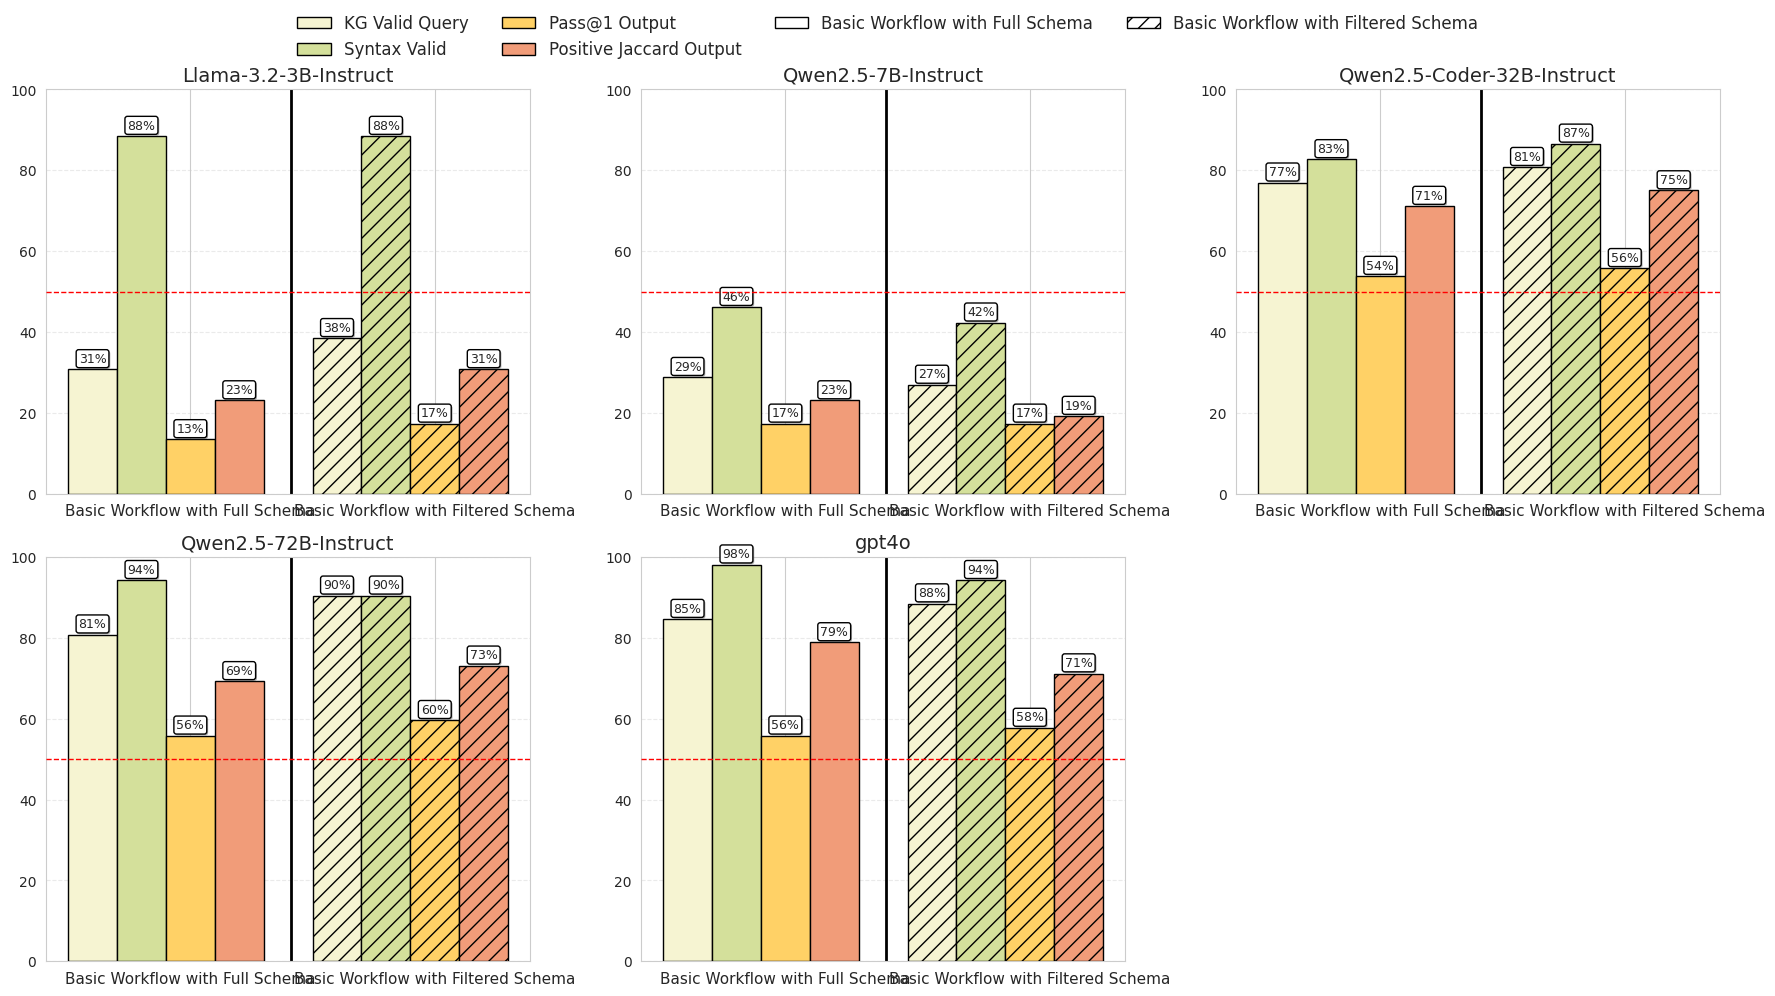

In [20]:
metrics_plot = melted_result[melted_result['Metric'].isin(['KG Valid Query','Syntax Valid','Pass@1 Output','Positive Jaccard Output'])].reset_index(drop=True)
metrics_copy = metrics_plot.copy()

total_df = melted_result[melted_result['Metric']=='Total']

metrics = ['KG Valid Query', 'Syntax Valid', 'Pass@1 Output', 'Positive Jaccard Output']
phases = ['Basic Workflow with Full Schema', 'Basic Workflow with Filtered Schema']
models = metrics_copy['Model'].unique()

colors = {
    'KG Valid Query': '#f6f4d2',
    'Syntax Valid': '#d4e09b',
    'Pass@1 Output': '#ffd166',
    'Positive Jaccard Output': '#f19c79'
}

hatches = {
    'Basic Workflow with Full Schema': '',
    'Basic Workflow with Filtered Schema': '//'
}

# Plot settings
n_cols = 3
n_rows = int(np.ceil(len(models) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 10))
axes = axes.flatten()

bar_width = 0.2
x_ticks = []
x_labels = []

for i, model in enumerate(models):
    ax = axes[i]
    xpos = []
    heights = []
    colors_list = []
    hatches_list = []

    x_base = 0

    for phase in phases:
        for j, metric in enumerate(metrics):
            xpos.append(x_base + j * bar_width)
            x_labels.append(metric if phase == phases[0] else '')
            x_ticks.append(x_base + j * bar_width)
            
            # Get height
            value_df = metrics_copy[
                (metrics_copy['Model'] == model) &
                (metrics_copy['Metric'] == metric) &
                (metrics_copy['Phase'] == phase)
            ]
            if not value_df.empty:
                value = value_df['Count'].values[0] / len_df * 100
            else:
                value = 0
            heights.append(value)
            colors_list.append(colors[metric])
            hatches_list.append(hatches[phase])

        x_base += len(metrics) * bar_width + 0.2  # space between phase groups

    # Draw bars
    bars = ax.bar(xpos, heights, width=bar_width,
                  color=colors_list, edgecolor='black',
                  hatch=None, zorder=3)

    for bar, hatch in zip(bars, hatches_list):
        bar.set_hatch(hatch)

    # Annotate
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.annotate(f'{height:.0f}%',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=9,
                        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.2',
                                  path_effects=[path_effects.withSimplePatchShadow(offset=(1, -1),
                                                                                    shadow_rgbFace='gray', alpha=0.6)]))
    ax.axvline(x=len(metrics) * bar_width + 0.01, color='black', linewidth=2)
    ax.axhline(y=50, color='red', linewidth=1,linestyle='--', label='50% Success',zorder=3) 
    ax.set_title(model, fontsize=14)
    ax.set_ylim(0, 100)
    ax.grid(True, axis='y', linestyle='--', alpha=0.4, zorder=0)
    ax.set_xticks([(i + 0.5 * (bar_width * len(metrics))) for i in [0, len(metrics) * bar_width + 0.2]])
    ax.set_xticklabels(phases, fontsize=11)

# Hide unused subplots
for j in range(len(models), len(axes)):
    fig.delaxes(axes[j])

# Legend
legend_elements = [
    plt.Rectangle((0, 0), 1, 1, facecolor=colors[m], edgecolor='black', label=m)
    for m in metrics
] + [
    plt.Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='black', hatch=hatches[p], label=p)
    for p in phases
]
fig.legend(handles=legend_elements, loc='upper center', ncol=4, fontsize=12, frameon=False)

# fig.suptitle("Per-Model Performance on 4 Metrics Across Two Phases", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


## Subplot per metric with change arrow

In [21]:
main_metrics = ['Average JaRou Score', 'KG Valid Query','Positive Jaccard Output', 'Pass@1 Output']
cypher_metrics = [ 'Average BLUE score','Average Jaccard similarity score',
                    'Average Jaro-Winkler similarity score', 'Average Rouge-L F1-score']

### Main metrics

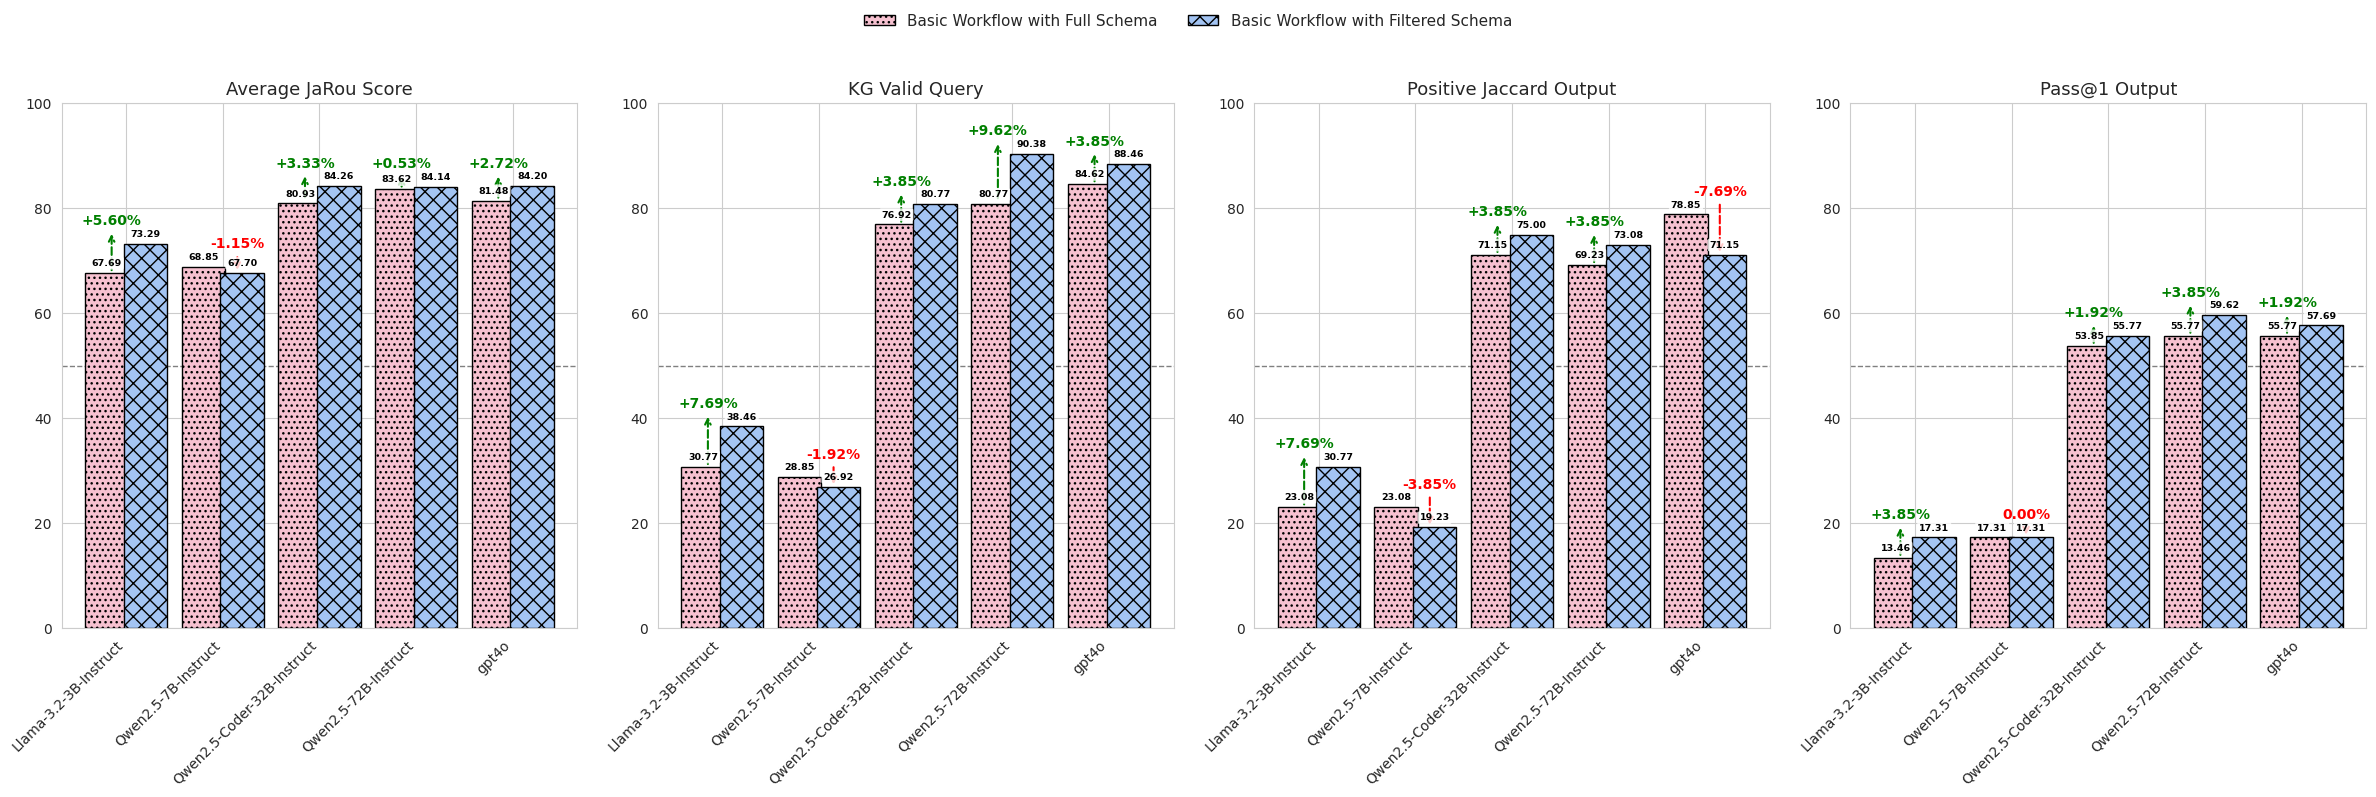

In [22]:
metrics = main_metrics
# metrics = cypher_metrics

metrics_plot = melted_result[melted_result['Metric'].isin(metrics)].reset_index(drop=True)
metrics_copy = metrics_plot.copy()

total_df = melted_result[melted_result['Metric']=='Total']
colors = ['#f6c1d0', '#a3c4f3']
hatches = ['...', 'xx']
phases = ['Basic Workflow with Full Schema', 'Basic Workflow with Filtered Schema']
models = metrics_copy['Model'].unique()

fig, axes = plt.subplots(1, 4, figsize=(24, 8))  # 2 rows, 4 columns
axes = axes.flatten()

for idx, metric in enumerate(metrics):
    ax = axes[idx]

    for i, model in enumerate(models):
        vals = []
        for phase in phases:
            val = metrics_copy[
                (metrics_copy['Model'] == model) &
                (metrics_copy['Metric'] == metric) &
                (metrics_copy['Phase'] == phase)
            ]['Count'].values

            if len(val) > 0:
                if idx == 0:
                    percentage = val[0] * 100  #  Scale raw score to percent
                else:
                    total_val = total_df[
                        (total_df['Model'] == model) &
                        (total_df['Phase'] == phase)
                    ]['Count'].values
                    percentage = val[0] / total_val[0] * 100
            else:
                percentage = 0

            vals.append(percentage)

        bar_x = [i - 0.2, i + 0.2]
        bars = ax.bar(bar_x, vals, width=0.45,
                      color=colors,
                      edgecolor='black',
                      hatch=hatches,
                      zorder=3)

        # Optional: add arrows for differences
        if len(vals) == 2:
            basic, extended = vals[0], vals[1]
            diff = extended - basic
            sign = '+' if diff > 0 else ''
            diff_text = f'{sign}{diff:.2f}%'

            if diff > 0:
                # Gain: annotate above the left bar (Basic)
                bar_x = i - 0.15
                base_val = basic
                arrow_color = 'green'
                arrowstyle = '<-'
            else:
                # Drop: annotate above the right bar (Extended)
                bar_x = i + 0.15
                base_val = extended
                arrow_color = 'red'
                arrowstyle = '->'

            y_end = max(basic, extended) + 3

            ax.annotate(
                diff_text,
                xy=(bar_x, base_val),
                xytext=(bar_x, y_end),
                arrowprops=dict(
                    arrowstyle=arrowstyle,
                    color=arrow_color,
                    lw=1.5,
                    linestyle='dashed'
                ),
                ha='center',
                va='bottom',
                color=arrow_color,
                fontsize=10,
                fontweight='bold'
            )

            # if extended > basic:
            #     ax.annotate(
            #         diff_text,
            #         xy=(i - 0.15, basic),
            #         xytext=(i - 0.15, extended + 2),
            #         arrowprops=dict(arrowstyle='<-', color='green', lw=1.5, linestyle='dashed'),
            #         ha='center',
            #         va='bottom',
            #         color='green',
            #         fontsize=10,
            #         fontweight='bold'
            #     )

        # Add score label above each bar
        for bar in bars:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,  # center of the bar
                height + 1,                         # a bit above the top
                f'{height:.2f}',                   # format as percentage
                ha='center',
                va='bottom',
                fontsize=6.8,
                fontweight='bold',
                color='black',
                bbox=dict(
                    facecolor='white',
                    edgecolor='none',
                    alpha=0.8,
                    boxstyle='round,pad=0.2'
                )
            )
      

    ax.set_title(f'{metric}', fontsize=13)
    # wrapped_labels =  ['Llama-3.2-3B-Instruct', 'Llama-3.1-8B-Instruct','Finetuned-\nAzzede-Llama-3.1-8b',
    #    'gemma-2-9b-it', 'Finetuned-\nNeo4j-gemma-2-9b-it','gpt4o']

    ax.set_xticks(range(len(models)))
    ax.set_xticklabels(models, rotation=45, ha='right')

    # ✅ Make all axes consistent (0–100)
    ax.set_ylim(0, 100)
    ax.axhline(y=50, linestyle='--', color='gray', linewidth=1)


# Legend
handles = [
    mpatches.Patch(facecolor=colors[0], hatch=hatches[0], edgecolor='black', label='Basic Workflow with Full Schema'),
    mpatches.Patch(facecolor=colors[1], hatch=hatches[1], edgecolor='black', label='Basic Workflow with Filtered Schema'),
]
fig.legend(handles=handles, loc='upper center', ncol=2, fontsize=11, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


### Cypher metrics

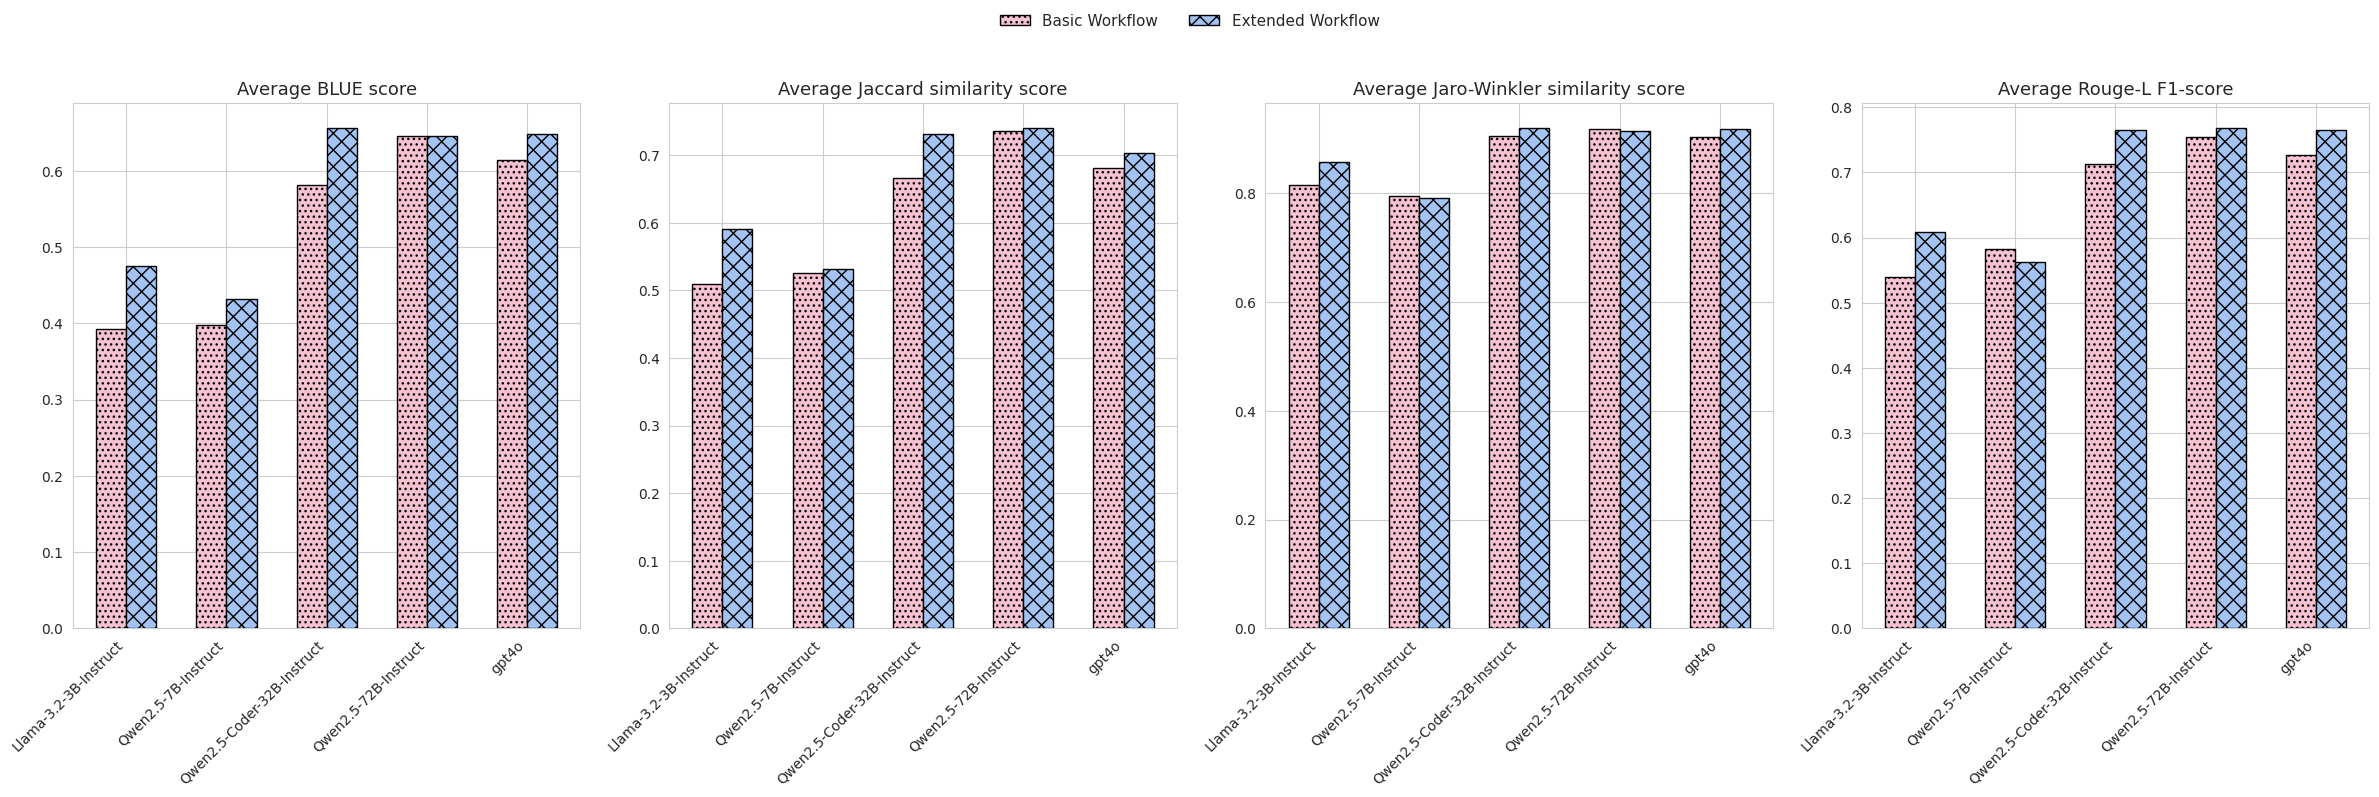

In [23]:
metrics = cypher_metrics

metrics_plot = melted_result[melted_result['Metric'].isin(metrics)].reset_index(drop=True)
metrics_copy = metrics_plot.copy()

total_df = melted_result[melted_result['Metric']=='Total']
colors = ['#f6c1d0', '#a3c4f3']
hatches = ['...', 'xx']

fig, axes = plt.subplots(1, 4, figsize=(24, 8))  # 2 rows, 4 columns
axes = axes.flatten()

for idx, metric in enumerate(metrics):
    ax = axes[idx]

    for i, model in enumerate(models):
        vals = []
        for phase in phases:
            val = metrics_copy[
                (metrics_copy['Model'] == model) &
                (metrics_copy['Metric'] == metric) &
                (metrics_copy['Phase'] == phase)
            ]['Count'].values

            total_val = total_df[
                (total_df['Model'] == model) &
                (total_df['Metric'] == 'Total') &
                (total_df['Phase'] == phase)
            ]['Count'].values
            percentage = val[0] if len(val) > 0 else 0
            vals.append(percentage)

        bar_x = [i - 0.15, i + 0.15]
        bars = ax.bar(bar_x, vals, width=0.3,
                      color=colors,
                      edgecolor='black',
                      hatch=hatches,
                      zorder=3)
        
    # # Add bar value
    #     for j, rect in enumerate(bars):
    #         height = rect.get_height()
    #         ax.text(
    #                 rect.get_x() + rect.get_width() / 2,  # x = center of the bar
    #                 height + 1,                           # y = 1 unit above the bar
    #                 f'{height:.3f}',
    #                 ha='center',
    #                 va='bottom',
    #                 fontsize=7,
    #                 bbox=dict(
    #                     facecolor='white',
    #                     edgecolor='black',
    #                     boxstyle='round,pad=0.2',
    #                     path_effects=[path_effects.withSimplePatchShadow(offset=(1, -1), shadow_rgbFace='gray', alpha=0.6)]
    #                 )
    #             )


    ax.set_title(f'{metric}', fontsize=13)
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels(models, rotation=45, ha='right')

    # Set y-axis limits
    if metric in cypher_metrics:
        ax.set_ylim(auto=True)  # dynamic
    else:
        ax.set_ylim(0, 100)
        ax.axhline(y=50, linestyle='--', color='gray', linewidth=1)

# Legend
handles = [
    mpatches.Patch(facecolor=colors[0], hatch=hatches[0], edgecolor='black', label='Basic Workflow'),
    mpatches.Patch(facecolor=colors[1], hatch=hatches[1], edgecolor='black', label='Extended Workflow'),
]
fig.legend(handles=handles, loc='upper center', ncol=2, fontsize=11, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

# LLMetric

## Percentage Change on LLMetric components

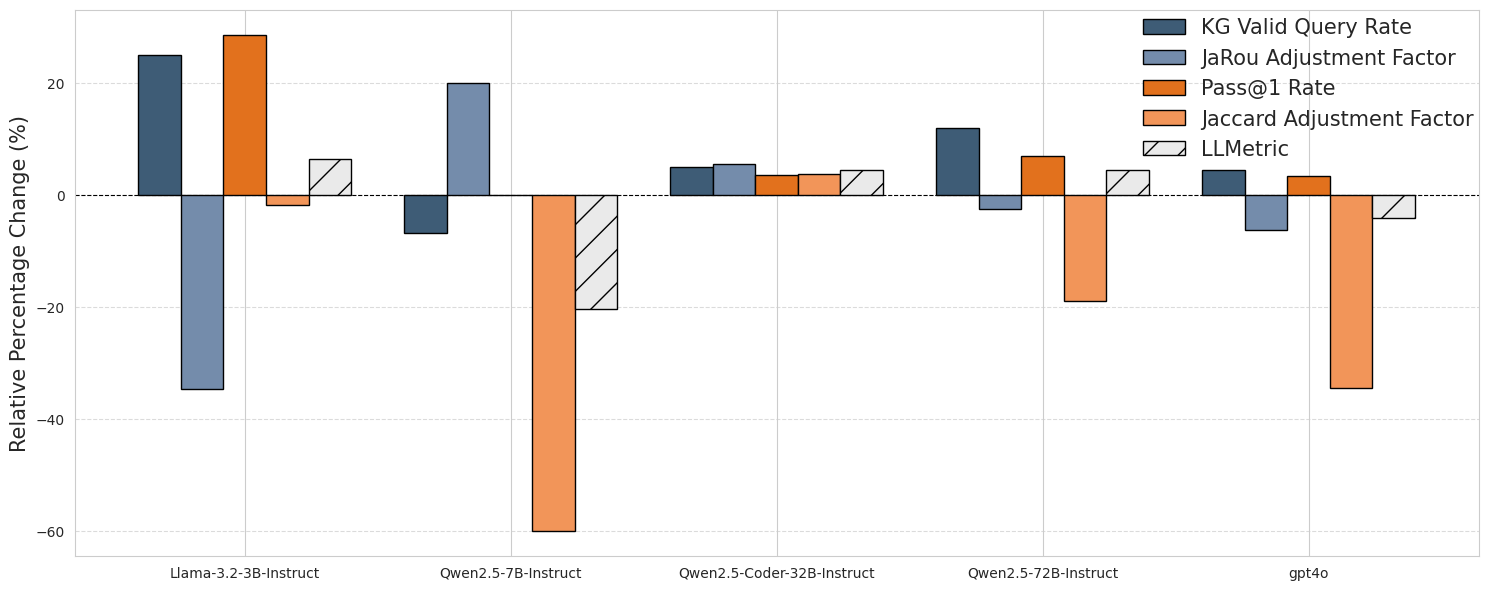

In [24]:
# Filter and prepare the data
selected_metrics = ['KG Valid Query Rate',
                     'JaRou Adjustment Factor', 
                     'Pass@1 Rate',
                    'Jaccard Adjustment Factor', 
                    'LLMetric']

colors = ['#3e5c76','#748cab','#e2711d','#f29559','#EAEAEA']
hatches = [''] * (len(selected_metrics) - 1) + ['/']  # Hatch only the last bar group

change_df = melted_result[melted_result['Metric'].isin(selected_metrics)].reset_index(drop=True)

# Pivot and compute percentage change
pivot_df = (
    change_df
    .pivot_table(index=['Model', 'Metric'], columns='Phase', values='Count')
    .reset_index()
)

pivot_df['Percentage Change'] = (
    (pivot_df['Basic Workflow with Filtered Schema'] - pivot_df['Basic Workflow with Full Schema']) / pivot_df['Basic Workflow with Full Schema']
).round(3) * 100  # Round after calc to preserve accuracy

# Sort models and metrics
pivot_df['Model'] = pd.Categorical(pivot_df['Model'], categories=models, ordered=True)
pivot_df['Metric'] = pd.Categorical(pivot_df['Metric'], categories=selected_metrics, ordered=True)
pivot_df_sorted = pivot_df.sort_values(by=['Model', 'Metric'])

# Create value matrix
pivot_table = pivot_df_sorted.pivot(index='Model', columns='Metric', values='Percentage Change')
models_ordered = pivot_table.index
metrics_ordered = pivot_table.columns
values = pivot_table.values

# Plot
bar_width = 0.8 / len(metrics_ordered)
x = np.arange(len(models_ordered))

fig, ax = plt.subplots(figsize=(15, 6))

for i, (metric, color, hatch) in enumerate(zip(metrics_ordered, colors, hatches)):
    offsets = -0.4 + i * bar_width + bar_width / 2
    ax.bar(
        x + offsets,
        values[:, i],
        width=bar_width,
        label=metric,
        color=color,
        edgecolor='black',
        hatch=hatch,
        zorder=3
    )

# Final formatting
ax.set_xticks(x)
ax.set_xticklabels(models_ordered)
ax.set_ylabel('Relative Percentage Change (%)',size=15)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--', zorder=2)
ax.legend(title="", loc='upper right',bbox_to_anchor=(1.01, 1.02),fontsize=15,framealpha=0)  # Legend outside
ax.grid(axis='y', linestyle='--', alpha=0.7,zorder=1)

plt.tight_layout()
plt.show()


## LLMetric Original Values Side by Side

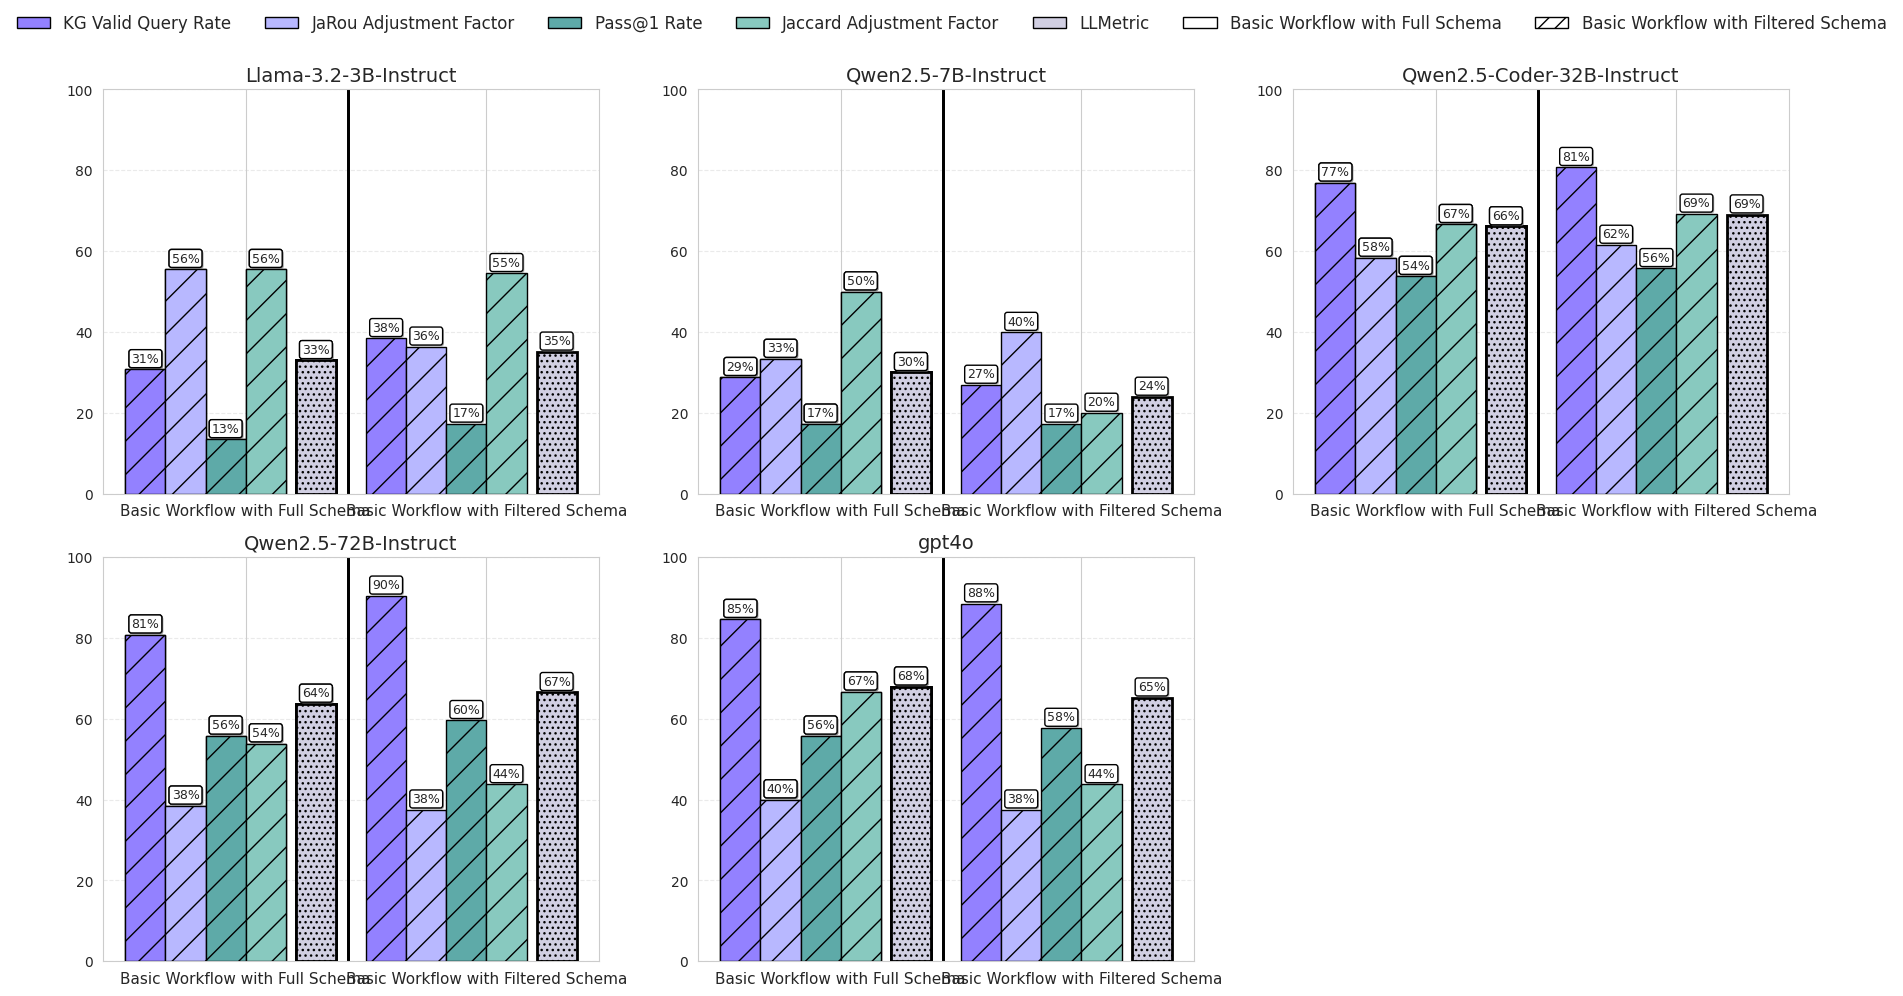

In [25]:
metrics = ['KG Valid Query Rate','JaRou Adjustment Factor','Pass@1 Rate','Jaccard Adjustment Factor','LLMetric']
llmetric_df = melted_result[melted_result['Metric'].isin(metrics)].reset_index(drop=True)
phases = ['Basic Workflow with Full Schema', 'Basic Workflow with Filtered Schema']
models = llmetric_df['Model'].unique()

colors = {
    'KG Valid Query Rate': '#9381ff',        # pastel light blue
    'JaRou Adjustment Factor': '#b8b8ff',    # pastel medium blue
    'Pass@1 Rate': '#5eaaa8',                 # pastel teal
    'Jaccard Adjustment Factor': '#88c9bf',  # muted teal
    'LLMetric': '#d1cfe2'                    # pastel purple
}

hatches = {
    'Basic Workflow with Full Schema': '',
    'Basic Workflow with Filtered Schema': '//'
}

# Plot settings
n_cols = 3
n_rows = int(np.ceil(len(models) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 10))
axes = axes.flatten()

bar_width = 0.2
x_ticks = []
x_labels = []

for i, model in enumerate(models):
    ax = axes[i]
    xpos,heights,colors_list,hatches_list,lw_list = [],[],[],[],[]
    x_base = 0

    for phase in phases:
        for j, metric in enumerate(metrics):
            xpos_value = x_base + j * bar_width

            if j == len(metrics) - 1:
                xpos_value += 0.05  # small space between last two bars
                lw = 2
                hatch = '...'
            else:
                lw=1
                if phase=='Basic Workflow':
                    hatch = ''
                else:
                    hatch ='/'

            xpos.append(xpos_value)
            x_labels.append(metric if phase == phases[0] else '')
            x_ticks.append(xpos_value)

            value_df = llmetric_df[
                (llmetric_df['Model'] == model) &
                (llmetric_df['Metric'] == metric) &
                (llmetric_df['Phase'] == phase)
            ]
            value = value_df['Count'].values[0] if not value_df.empty else 0
            heights.append(value)
            colors_list.append(colors[metric])
            hatches_list.append(hatch)
            lw_list.append(lw)

        x_base += len(metrics) * bar_width + 0.2

        # Draw bars
        bars = ax.bar(xpos, heights, width=bar_width,
                    color=colors_list, edgecolor='black',
                    hatch=None, zorder=3)
        
        # bars[-4].set_linewidth(2)  # thicker edge for last bar

        for bar, hatch,lw in zip(bars, hatches_list,lw_list):
            bar.set_hatch(hatch)
            bar.set_linewidth(lw)
        
        bars[-1].set_linewidth(2)  # thicker edge for last bar

        # Annotate
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax.annotate(f'{height:.0f}%',
                            xy=(bar.get_x() + bar.get_width() / 2, height),
                            xytext=(0, 3), textcoords="offset points",
                            ha='center', va='bottom', fontsize=9,
                            bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.2',
                                    path_effects=[path_effects.withSimplePatchShadow(offset=(1, -1),
                                                                                        shadow_rgbFace='gray', alpha=0.6)]))
        ax.axvline(x=len(metrics) * bar_width + 0.01, color='black', linewidth=2)
        # ax.axhline(y=50, color='red', linewidth=1,linestyle='--', label='50% Success',zorder=3) 
        ax.set_title(model, fontsize=14)
        ax.set_ylim(0, 100)
        ax.grid(True, axis='y', linestyle='--', alpha=0.4, zorder=0)
        ax.set_xticks([(i + 0.5 * (bar_width * len(metrics))) for i in [0, len(metrics) * bar_width + 0.2]])
        ax.set_xticklabels(phases, fontsize=11)

# Hide unused subplots
for j in range(len(models), len(axes)):
    fig.delaxes(axes[j])

# Legend
legend_elements = [
    plt.Rectangle((0, 0), 1, 1, facecolor=colors[m], edgecolor='black', label=m)
    for m in metrics
] + [
    plt.Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='black', hatch=hatches[p], label=p)
    for p in phases
]
fig.legend(handles=legend_elements, loc='upper center',ncol=8, fontsize=12, frameon=False)

# fig.suptitle("Per-Model Performance on 4 Metrics Across Two Phases", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
